# Импорт бибилиотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV,ElasticNetCV, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("AmesHousing.csv")
df = df[["Overall Qual", "Year Built", "Gr Liv Area",
         "Full Bath", "Garage Cars", "Garage Area", "SalePrice"]]
df["Garage Cars"] = df["Garage Cars"].fillna(df["Garage Cars"].median())
df["Garage Area"] = df["Garage Area"].fillna(df["Garage Area"].median())

df = pd.get_dummies(df, drop_first=True)

X = df.drop(["SalePrice"], axis=1)
y = df["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train=scaler.fit_transform(X_train) 
X_test=scaler.transform(X_test)

corr_matrix = X.corr()

print("Матрица корреляций")
display(corr_matrix.round(2))

Матрица корреляций


,Overall Qual,Year Built,Gr Liv Area,Full Bath,Garage Cars,Garage Area
Overall Qual,1.00,0.60,0.57,0.52,0.60,0.56
Year Built,0.60,1.00,0.24,0.47,0.54,0.48
Gr Liv Area,0.57,0.24,1.00,0.63,0.49,0.48
Full Bath,0.52,0.47,0.63,1.00,0.48,0.41
Garage Cars,0.60,0.54,0.49,0.48,1.00,0.89
Garage Area,0.56,0.48,0.48,0.41,0.89,1.00


## Для прогноза SalePrice выбраны шесть числовых признаков (качество дома, год постройки, жилая площадь, количество ванных, вместимость и площадь гаража), так как признаков слишком много и наглядность страдает. Корреляция вместимости и площади гаража равна 0,890 и превышает порог 0,85, значит они линейно зависимы

In [3]:
lr = LinearRegression()
lr.fit(X_train, y_train)

alphas_to_test = [0.1, 1.0, 10.0, 100.0, 1000.0, 2000.0, 3000.0, 5000.0, 10000.0]
ridge_cv = RidgeCV(alphas=alphas_to_test)
ridge_cv.fit(X_train, y_train)


lasso_cv =LassoCV(alphas=alphas_to_test, random_state=42)
lasso_cv.fit(X_train, y_train)
lasso =Lasso(alpha=5000.0, random_state=42)
lasso.fit(X_train, y_train)
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]
elastic_cv = ElasticNetCV(l1_ratio=l1_ratios, alphas=alphas_to_test, cv=5, random_state=42)
elastic_cv.fit(X_train, y_train)

print(f"alpha l2= {ridge_cv.alpha_}")
print(f"alpha l1 = {lasso_cv.alpha_}")
print(f"alpha l1/l2 = {elastic_cv.alpha_}")
print(f"Оптимальное соотношение L1/L2 (l1_ratio): {elastic_cv.l1_ratio_}")

print("Веса OLS")
print(np.round(lr.coef_, 0))
print("Веса Ridge (L2)")
print(np.round(ridge_cv.coef_, 0))
print("Веса Lasso (L1)")
print(np.round(lasso_cv.coef_, 0))
print("Веса Lasso (L1) (alpha = 5000)")
print(np.round(lasso.coef_, 0))
print("Веса ElasticNet:")
print(np.round(elastic_cv.coef_, 0))

alpha l2= 10.0
alpha l1 = 100.0
alpha l1/l2 = 1.0
Оптимальное соотношение L1/L2 (l1_ratio): 0.99
Веса OLS
[32021. 13541. 30179. -4835.  2733.  9902.]
Веса Ridge (L2)
[31878. 13446. 29959. -4621.  2904.  9853.]
Веса Lasso (L1)
[32009. 13347. 29899. -4450.  2662.  9943.]
Веса Lasso (L1) (alpha = 5000)
[31724.  8562. 24140.     0.  1834.  9152.]
Веса ElasticNet:
[31688. 13322. 29669. -4339.  3120.  9796.]


## Для Ridge автоматически выбрано alpha = 10, для Lasso - alpha = 100. Lasso с ручным alpha = 5000 обнулила вес количества ванных комнат. Остальные модели сохранили все признаки. Коэффициенты остались конечными, астрономических значений нет

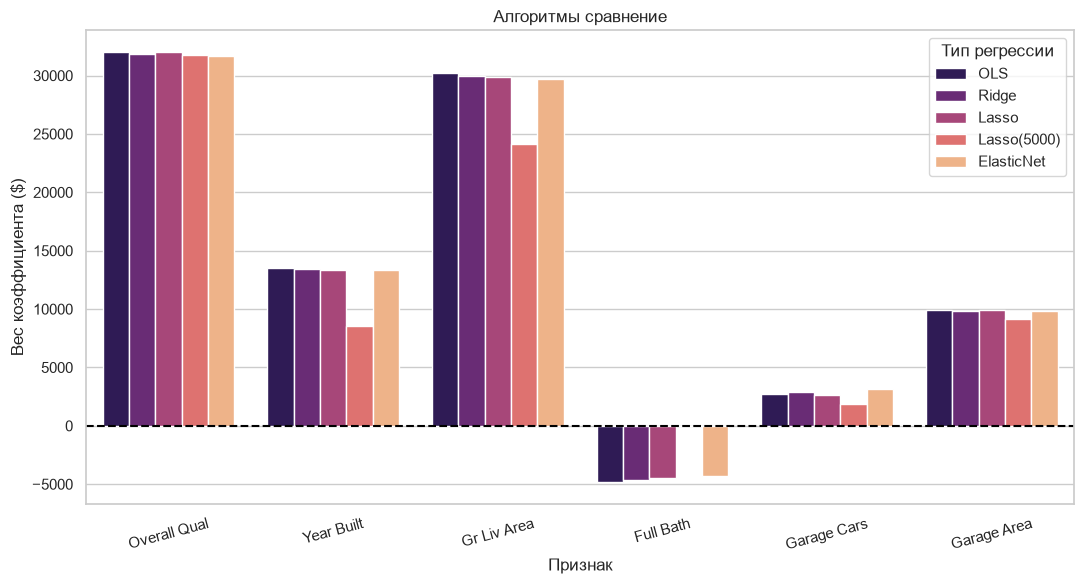

In [4]:
weights_df = pd.DataFrame(
    {
        "Признак" : X.columns,
        "OLS" : lr.coef_,
        "Ridge" : ridge_cv.coef_,
        "Lasso" : lasso_cv.coef_,
        "Lasso(5000)" : lasso.coef_,
        "ElasticNet": elastic_cv.coef_
    }
)
weights_melted = weights_df.melt(
    id_vars="Признак", var_name="Модель", value_name="Влияние на цену (Вес)" 
)
plt.figure(figsize=(11,6))
sns.barplot(
    data=weights_melted,
    x="Признак",
    y="Влияние на цену (Вес)",
    hue="Модель",
    palette="magma"
)

plt.axhline(0, color="black", lw=1.5, ls="--")
plt.title("Алгоритмы сравнение")
plt.ylabel("Вес коэффициента ($)", fontsize=12)
plt.xticks(rotation=15)
plt.legend(title="Тип регрессии")
plt.tight_layout()
plt.show()

## Самые большие положительные веса получили качество дома и жилая площадь. Ridge немного изменила веса, Lasso со штрафом 5000 убрала из расчёта количество ванных комнат, поэтому модель использует 5 признаков

In [5]:
print(f"R2 для OLS: {r2_score(y_test, lr.predict(X_test)):.4f}")
print(f"R2 для Ridge: {r2_score(y_test, ridge_cv.predict(X_test)):.4f}")
print(f"R2 для Lasso: {r2_score(y_test, lasso_cv.predict(X_test)):.4f}")
print(f"R2 для Lasso: {r2_score(y_test, lasso.predict(X_test)):.4f}")
print(f"R2 для ElasticNet: {r2_score(y_test, elastic_cv.predict(X_test)):.4f}")

R2 для OLS: 0.7754
R2 для Ridge: 0.7750
R2 для Lasso: 0.7751
R2 для Lasso: 0.7573
R2 для ElasticNet: 0.7746


## У обычной линейной регрессии R2 получился 0,7754. Ridge, Lasso и ElasticNet показали почти такие же результаты. У Lasso со штрафом 5000 R2 снизился до 0,7573. Получается, что эта модель стала проще, но предсказывает цену немного хуже

## Финальный бизнес-вывод
Для предсказания стоимости дома сравнили несколько моделей. У обычной линейной регрессии R2 = 0,7754, у Ridge - 0,7750, у Lasso - 0,7751, у ElasticNet - 0,7746. Эти результаты почти одинаковые
Lasso со штрафом 5000 сократила количество признаков с 6 до 5, убрав количество ванных комнат. При этом R2 снизился с 0,7754 до 0,7573, то есть на 0,0181. Модель стала немного проще, но качество предсказания цены снизилось. Очень больших весов у обычной регрессии на выбранных данных не было